In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
orders=pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
reviews = pd.read_csv("olist_order_reviews_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")

In [3]:
print(orders.shape)        # rows, columns
orders.head()

(99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
print(orders.isnull().sum())
orders.dtypes

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64


order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

In [5]:
date_cols = ["order_purchase_timestamp",
             "order_delivered_customer_date",
             "order_estimated_delivery_date"]

for col in date_cols:
    orders[col] = pd.to_datetime(orders[col])

# Keep only delivered orders that have a delivery date
orders = orders[orders["order_status"] == "delivered"].dropna(
    subset=["order_delivered_customer_date"]).copy()

print("Delivered orders:", len(orders))

Delivered orders: 96470


In [6]:
# Positive = late, negative = early
orders["delay_days"] = (orders["order_delivered_customer_date"]
                        - orders["order_estimated_delivery_date"]).dt.days
orders["is_late"] = orders["delay_days"] > 0

print("Percent late:", round(orders["is_late"].mean() * 100, 1), "%")
print("Median delay (days):", orders["delay_days"].median())

Percent late: 6.8 %
Median delay (days): -12.0


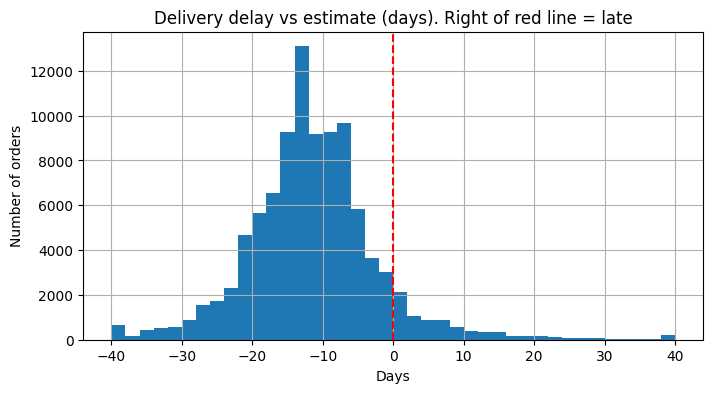

In [7]:
plt.figure(figsize=(8, 4))
orders["delay_days"].clip(-40, 40).hist(bins=40)
plt.axvline(0, color="red", linestyle="--")
plt.title("Delivery delay vs estimate (days). Right of red line = late")
plt.xlabel("Days")
plt.ylabel("Number of orders")
plt.show()

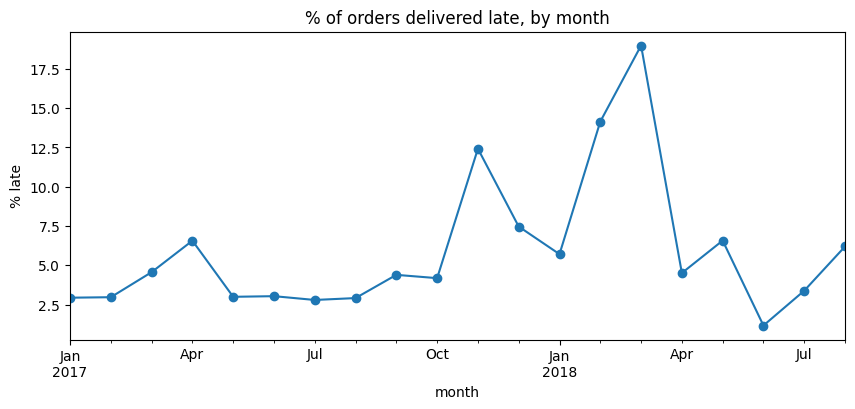

In [8]:
recent = orders[orders["order_purchase_timestamp"] >= "2017-01-01"].copy()
recent["month"] = recent["order_purchase_timestamp"].dt.to_period("M")

monthly = recent.groupby("month")["is_late"].mean() * 100

plt.figure(figsize=(10, 4))
monthly.plot(marker="o")
plt.title("% of orders delivered late, by month")
plt.ylabel("% late")
plt.show()

In [9]:
merged = orders.merge(customers, on="customer_id")

by_state = merged.groupby("customer_state").agg(
    total_orders=("order_id", "count"),
    late_pct=("is_late", lambda x: round(x.mean() * 100, 1))
).sort_values("late_pct", ascending=False)

by_state.head(10)

,total_orders,late_pct
customer_state,,
AL,397,21.4
MA,717,17.4
SE,335,15.2
PI,476,13.9
CE,1279,13.8
BA,3256,12.2
RR,41,12.2
RJ,12350,12.1
PA,946,11.2


In [10]:
reviews = reviews.drop_duplicates("order_id")   # some orders have 2 reviews

with_reviews = orders.merge(reviews[["order_id", "review_score"]], on="order_id")

with_reviews.groupby("is_late")["review_score"].mean().round(2)

is_late
False    4.29
True     2.27
Name: review_score, dtype: float64

In [11]:
order_sellers = items[["order_id", "seller_id"]].drop_duplicates()
seller_perf = order_sellers.merge(orders[["order_id", "is_late"]], on="order_id")

seller_stats = seller_perf.groupby("seller_id").agg(
    total_orders=("order_id", "count"),
    late_pct=("is_late", lambda x: round(x.mean() * 100, 1))
)

# Only sellers with at least 30 orders, so the percentages are meaningful
seller_stats[seller_stats["total_orders"] >= 30].sort_values(
    "late_pct", ascending=False).head(10)

,total_orders,late_pct
seller_id,,
ede0c03645598cdfc63ca8237acbe73d,43,32.6
ad781527c93d00d89a11eecd9dcad7c1,38,31.6
54965bbe3e4f07ae045b90b0b8541f52,73,30.1
2a1348e9addc1af5aaa619b1a3679d6b,48,27.1
835f0f7810c76831d6c7d24c7a646d4d,42,26.2
beadbee30901a7f61d031b6b686095ad,64,23.4
a49928bcdf77c55c6d6e05e09a9b4ca5,96,21.9
ef990a83bbea832f36ebe81376335aa8,43,20.9
712e6ed8aa4aa1fa65dab41fed5737e4,77,20.8


In [12]:
orders["actual_days"] = (orders["order_delivered_customer_date"]
                         - orders["order_purchase_timestamp"]).dt.days
orders["estimated_days"] = (orders["order_estimated_delivery_date"]
                            - orders["order_purchase_timestamp"]).dt.days

orders[["actual_days", "estimated_days"]].describe().round(1)

,actual_days,estimated_days
count,96470.0,96470.0
mean,12.1,23.4
std,9.6,8.8
min,0.0,2.0
25%,6.0,18.0
50%,10.0,23.0
75%,15.0,28.0
max,209.0,155.0


In [13]:
merged = orders.merge(customers, on="customer_id")

state_times = merged.groupby("customer_state").agg(
    orders=("order_id", "count"),
    avg_actual=("actual_days", "mean"),
    avg_estimated=("estimated_days", "mean"),
    late_pct=("is_late", lambda x: round(x.mean() * 100, 1))
).round(1)

state_times[state_times["orders"] >= 100].sort_values("late_pct", ascending=False).head(10)

,orders,avg_actual,avg_estimated,late_pct
customer_state,,,,
AL,397,24.0,32.2,21.4
MA,717,21.1,30.1,17.4
SE,335,21.0,30.5,15.2
PI,476,19.0,29.7,13.9
CE,1279,20.8,31.0,13.8
BA,3256,18.9,29.1,12.2
RJ,12350,14.8,26.0,12.1
PA,946,23.3,36.8,11.2
ES,1995,15.3,25.2,10.7


In [14]:
late_by_seller = (seller_perf[seller_perf["is_late"]]
                  .groupby("seller_id").size()
                  .sort_values(ascending=False))

top_n = int(len(seller_stats) * 0.10)          # top 10% of all sellers
share = late_by_seller.head(top_n).sum() / late_by_seller.sum()

print(f"Top 10% of sellers cause {share:.0%} of all late orders")

Top 10% of sellers cause 74% of all late orders


In [15]:
import numpy as np

data = orders.merge(customers[["customer_id", "customer_state"]], on="customer_id")

cutoff = pd.Timestamp("2018-04-01")
train = data[data["order_purchase_timestamp"] < cutoff]
test = data[data["order_purchase_timestamp"] >= cutoff].copy()

print("Train orders:", len(train), "| Test orders:", len(test))

Train orders: 64320 | Test orders: 32150


In [16]:
def build_promise(q):
    by_state = train.groupby("customer_state")["actual_days"].quantile(q)
    overall = train["actual_days"].quantile(q)
    # look up each test order's state; use the overall value if a state is missing
    return np.ceil(test["customer_state"].map(by_state).fillna(overall))

In [17]:
rows = [{
    "method": "Olist's estimate",
    "avg_promised_days": test["estimated_days"].mean(),
    "late_pct": (test["actual_days"] > test["estimated_days"]).mean() * 100,
}]

for q in [0.85, 0.90, 0.95, 0.97]:
    promise = build_promise(q)
    rows.append({
        "method": f"State-level {int(q*100)}th percentile",
        "avg_promised_days": promise.mean(),
        "late_pct": (test["actual_days"] > promise).mean() * 100,
    })

results = pd.DataFrame(rows).round(1)
results

,method,avg_promised_days,late_pct
0,Olist's estimate,21.5,5.4
1,State-level 85th percentile,19.4,5.2
2,State-level 90th percentile,22.8,3.0
3,State-level 95th percentile,28.2,1.4
4,State-level 97th percentile,32.5,0.8


In [18]:
median_promise = build_promise(0.50)
print("Olist: average gap between promise and actual:",
      round((test["estimated_days"] - test["actual_days"]).abs().mean(), 1), "days")
print("State-median model gap:",
      round((median_promise - test["actual_days"]).abs().mean(), 1), "days")

Olist: average gap between promise and actual: 12.9 days
State-median model gap: 4.8 days
